# AI-Powered Job Market Intelligence & Salary Prediction System
## Step 6: Resume Skill Extraction & Parsing Engine (Module 3)

**Target Notebook:** `notebooks/06_resume_skill_extraction.ipynb`  
**Core Module:** `src/resume_parser.py`  
**Underlying Engine:** PyMuPDF (`fitz`), Regular Expressions, Curated Skill Taxonomy  

### Objectives & Strict Engineering Governance:
1. **Robust PDF Text Ingestion:** Parse multi-page PDF documents using PyMuPDF, preserving layout and line-breaks while gracefully handling scanned, empty, or corrupted files.
2. **Scanned PDF Diagnostics:** Accurately detect image-only PDFs lacking selectable text layers and emit explicit warnings explaining that OCR is not supported.
3. **Heuristic Section Segmentation:** Partition document content into canonical sections (`skills`, `experience`, `projects`, `education`, `certifications`) without hallucinating missing fields.
4. **Curated Skill Taxonomy & Alias Normalization:** Match candidate skills against our canonical tech dictionary, standardizing variations (e.g., `py` $\rightarrow$ Python, `k8s` $\rightarrow$ Kubernetes, `sklearn` $\rightarrow$ Scikit-learn) with strict word-boundary protection to eliminate false positives.
5. **Zero Data Retention:** Process resume byte streams purely in memory without persistent storage, ensuring strict privacy and credential isolation.

In [1]:
# 1. Environment Setup & Library Imports
import os
import sys
import io
import json
import tempfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import pymupdf as fitz
except ImportError:
    import fitz

# Add project root to sys.path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.resume_parser import (
    ResumeParser,
    parse_resume,
    extract_text_from_pdf,
    extract_sections_from_text,
    extract_skills_from_text,
    CANONICAL_SKILL_PATTERNS
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

print(f'PyMuPDF Version: {fitz.__version__}')
print(f'Total Curated Canonical Skills in Taxonomy: {len(CANONICAL_SKILL_PATTERNS)}')
print('Resume Parser module imported successfully.')

PyMuPDF Version: 1.28.2
Total Curated Canonical Skills in Taxonomy: 43
Resume Parser module imported successfully.


### 2. Creation of Synthetic Test Resumes
To rigorously validate the parser without compromising private personal data, we synthesize four controlled test resumes covering diverse technical disciplines, seniorities, and edge cases:

In [2]:
# Create in-memory synthetic resumes
test_resumes = {}

# 1. Senior Data Scientist Resume (Multi-skill, Data & Cloud)
doc1 = fitz.open()
p1 = doc1.new_page()
text_ds = '''
Aditi Sharma
Bengaluru, Karnataka | aditi.sharma.sample@example.com

SUMMARY
Senior Data Scientist with 5+ years of experience leading machine learning, deep learning, and predictive modeling initiatives.

TECHNICAL SKILLS
Programming Languages: Python, SQL, C++
Machine Learning & AI: Scikit-learn, PyTorch, TensorFlow, NLP, Computer Vision, Statistics
Cloud & DevOps: AWS, Docker, Kubernetes, Git, Linux
Databases: PostgreSQL, Redis, MongoDB

PROFESSIONAL EXPERIENCE
Lead Data Scientist | FinTech Innovations (2022 - Present)
- Architected real-time fraud detection pipelines using Python, PyTorch, and Kafka, decreasing fraudulent transactions by 32%.
- Deployed scalable inference endpoints using FastAPI and Docker on AWS EKS.

Senior Machine Learning Engineer | DataCorp India (2019 - 2022)
- Engineered recommendation systems with Pandas, NumPy, and Scikit-learn on a 50M-record customer dataset.
- Orchestrated automated retraining pipelines with Apache Airflow and PostgreSQL.

PROJECTS
AI Market Intelligence Platform
- Built end-to-end salary forecasting models using XGBoost, FastAPI, and Streamlit.

EDUCATION
M.Tech in Artificial Intelligence - IISc Bengaluru (2017 - 2019)
B.Tech in Computer Science - NIT Karnataka (2013 - 2017)

CERTIFICATIONS
AWS Certified Machine Learning - Specialty
'''
p1.insert_text((50, 60), text_ds.strip())
test_resumes['Senior_Data_Scientist'] = doc1.tobytes()
doc1.close()

# 2. Full-Stack Cloud Developer Resume (Web, APIs, Cloud)
doc2 = fitz.open()
p2_1 = doc2.new_page()
text_fs_1 = '''
Rohan Verma
Hyderabad, Telangana

TECHNICAL SKILLS
Languages: JavaScript, TypeScript, Python, Java, HTML/CSS
Frameworks: React, Node.js, Django, FastAPI
Databases: MySQL, PostgreSQL, Redis
Cloud & Tools: GCP, Docker, Kubernetes, Git

WORK EXPERIENCE
Senior Full Stack Engineer | CloudTech Solutions (2021 - Present)
- Developed microservices using Node.js and FastAPI with React single-page frontend.
'''
p2_1.insert_text((50, 60), text_fs_1.strip())
p2_2 = doc2.new_page()
text_fs_2 = '''
PROJECTS
Enterprise Resource Dashboard
- Integrated React frontend with PostgreSQL and Redis cache.

EDUCATION
B.Tech in Information Technology - BITS Pilani (2017 - 2021)
'''
p2_2.insert_text((50, 60), text_fs_2.strip())
test_resumes['FullStack_Cloud_Developer'] = doc2.tobytes()
doc2.close()

# 3. Fresher Business Intelligence Analyst Resume (BI, Analytics, SQL)
doc3 = fitz.open()
p3 = doc3.new_page()
text_bi = '''
Kavya Nair
Pune, Maharashtra

CORE COMPETENCIES
Power BI, Tableau, Excel, SQL, Python, Statistics

PROJECTS
Sales Performance Analytics Dashboard
- Designed interactive executive dashboards in Power BI and Excel.
- Extracted and transformed retail sales records using SQL and Pandas.

EDUCATION
B.Sc in Statistics - Pune University (2020 - 2023)
'''
p3.insert_text((50, 60), text_bi.strip())
test_resumes['Fresher_BI_Analyst'] = doc3.tobytes()
doc3.close()

# 4. Scanned / Image-Only PDF (Edge Case: No Text Layer)
doc4 = fitz.open()
doc4.new_page()  # Blank page mimicking an image scan without selectable text
test_resumes['Scanned_Image_Resume'] = doc4.tobytes()
doc4.close()

print(f'Successfully generated {len(test_resumes)} synthetic test PDFs in memory.')

Successfully generated 4 synthetic test PDFs in memory.


### 3. PDF Text Extraction & Error Handling
Testing PyMuPDF text extraction across valid single-page, multi-page, and image-only documents.

In [3]:
for resume_name, pdf_data in test_resumes.items():
    extracted_text, page_count, warnings, status = extract_text_from_pdf(pdf_data)
    print(f'=== Resume: {resume_name} ===')
    print(f'  Status: {status} | Pages: {page_count} | Extracted Characters: {len(extracted_text)}')
    if warnings:
        print(f'  Warning: {warnings[0]}')
    else:
        print(f'  Snippet: {extracted_text[:120].replace(chr(10), " ")}...')
    print()

=== Resume: Senior_Data_Scientist ===
  Status: SUCCESS | Pages: 1 | Extracted Characters: 1264
  Snippet: Aditi Sharma Bengaluru, Karnataka | aditi.sharma.sample@example.com SUMMARY Senior Data Scientist with 5+ years of exper...

=== Resume: FullStack_Cloud_Developer ===
  Status: SUCCESS | Pages: 2 | Extracted Characters: 571
  Snippet: Rohan Verma Hyderabad, Telangana TECHNICAL SKILLS Languages: JavaScript, TypeScript, Python, Java, HTML/CSS Frameworks: ...

=== Resume: Fresher_BI_Analyst ===
  Status: SUCCESS | Pages: 1 | Extracted Characters: 342
  Snippet: Kavya Nair Pune, Maharashtra CORE COMPETENCIES Power BI, Tableau, Excel, SQL, Python, Statistics PROJECTS Sales Performa...

=== Resume: Scanned_Image_Resume ===
  Status: WARNING | Pages: 1 | Extracted Characters: 0



### 4. Resume Section Segmentation
Evaluating line-level section identification for Technical Skills, Experience, Projects, Education, and Certifications.

In [4]:
ds_text, _, _, _ = extract_text_from_pdf(test_resumes['Senior_Data_Scientist'])
sections = extract_sections_from_text(ds_text)

print('=== Section Segmentation for Senior Data Scientist ===')
for sec_name, content in sections.items():
    line_count = len(content.splitlines()) if content else 0
    preview = content.replace('\n', ' ')[:90] if content else '[EMPTY / NOT FOUND]'
    print(f'Section: {sec_name.upper():<15} | Lines: {line_count:<2} | Preview: {preview}...')


=== Section Segmentation for Senior Data Scientist ===


Section: SKILLS          | Lines: 4  | Preview: Programming Languages: Python, SQL, C++ Machine Learning & AI: Scikit-learn, PyTorch, Tens...
Section: EXPERIENCE      | Lines: 6  | Preview: Lead Data Scientist | FinTech Innovations (2022 - Present) - Architected real-time fraud d...
Section: PROJECTS        | Lines: 2  | Preview: AI Market Intelligence Platform - Built end-to-end salary forecasting models using XGBoost...
Section: EDUCATION       | Lines: 2  | Preview: M.Tech in Artificial Intelligence - IISc Bengaluru (2017 - 2019) B.Tech in Computer Scienc...
Section: CERTIFICATIONS  | Lines: 1  | Preview: AWS Certified Machine Learning - Specialty...


### 5. Technical Skill Extraction & Alias Normalization
Demonstrating alias resolution (e.g., `py` $\rightarrow$ Python, `k8s` $\rightarrow$ Kubernetes) and verifying that substrings inside unrelated words do not trigger false matches.

In [5]:
# Test Alias Mapping
alias_test_text = 'Candidate with strong expertise in py, k8s, postgres, sklearn, powerbi, and dl pipelines.'
detected_aliases = extract_skills_from_text(alias_test_text)
print('=== Alias Resolution Test ===')
print(f'Input Text: "{alias_test_text}"')
print(f'Extracted Canonical Skills: {detected_aliases}')

# Test False-Positive Protection
adversarial_text = 'She is reacting positively to a table in the office while spying on an excellent cat going home.'
false_matches = extract_skills_from_text(adversarial_text)
print('\n=== False-Positive Protection Test ===')
print(f'Input Text: "{adversarial_text}"')
print(f'Extracted Skills (Expected: None): {false_matches}')
assert len(false_matches) == 0, 'False positive match detected!'

=== Alias Resolution Test ===
Input Text: "Candidate with strong expertise in py, k8s, postgres, sklearn, powerbi, and dl pipelines."
Extracted Canonical Skills: ['Deep Learning', 'Kubernetes', 'PostgreSQL', 'Power BI', 'Python', 'Scikit-learn']

=== False-Positive Protection Test ===
Input Text: "She is reacting positively to a table in the office while spying on an excellent cat going home."
Extracted Skills (Expected: None): []


### 6. End-to-End Structured Resume Parsing
Executing `parse_resume(...)` across all candidate resumes and inspecting the structured JSON output.

In [6]:
parsed_records = []

for resume_name, pdf_bytes in test_resumes.items():
    res = parse_resume(pdf_bytes, filename=f'{resume_name}.pdf')
    parsed_records.append({
        'Resume Profile': resume_name.replace('_', ' '),
        'Status': res['extraction_status'],
        'Skills Count': res['skill_count'],
        'Skills Extracted': ', '.join(res['extracted_skills']) if res['extracted_skills'] else '[None]',
        'Sections Identified': ', '.join([k for k, v in res['sections'].items() if v]),
        'Warning': res['warnings'][0] if res['warnings'] else '[None]'
    })

summary_df = pd.DataFrame(parsed_records)
summary_df

,Resume Profile,Status,Skills Count,Skills Extracted,Sections Identified,Warning
0,Senior Data Scientist,SUCCESS,24,"AWS, Airflow, C++, Computer Vision, Deep Learn...","skills, experience, projects, education, certi...",[None]
1,FullStack Cloud Developer,SUCCESS,16,"Django, Docker, FastAPI, GCP, Git, HTML/CSS, J...","skills, experience, projects, education",[None]
2,Fresher BI Analyst,SUCCESS,7,"Excel, Pandas, Power BI, Python, SQL, Statisti...","skills, projects, education",[None]
3,Scanned Image Resume,WARNING,0,[None],,Document appears to be a scanned image or cont...


### 7. Visualizing Skill Extraction Frequencies
Visualizing the technical competencies detected across our test corpus.

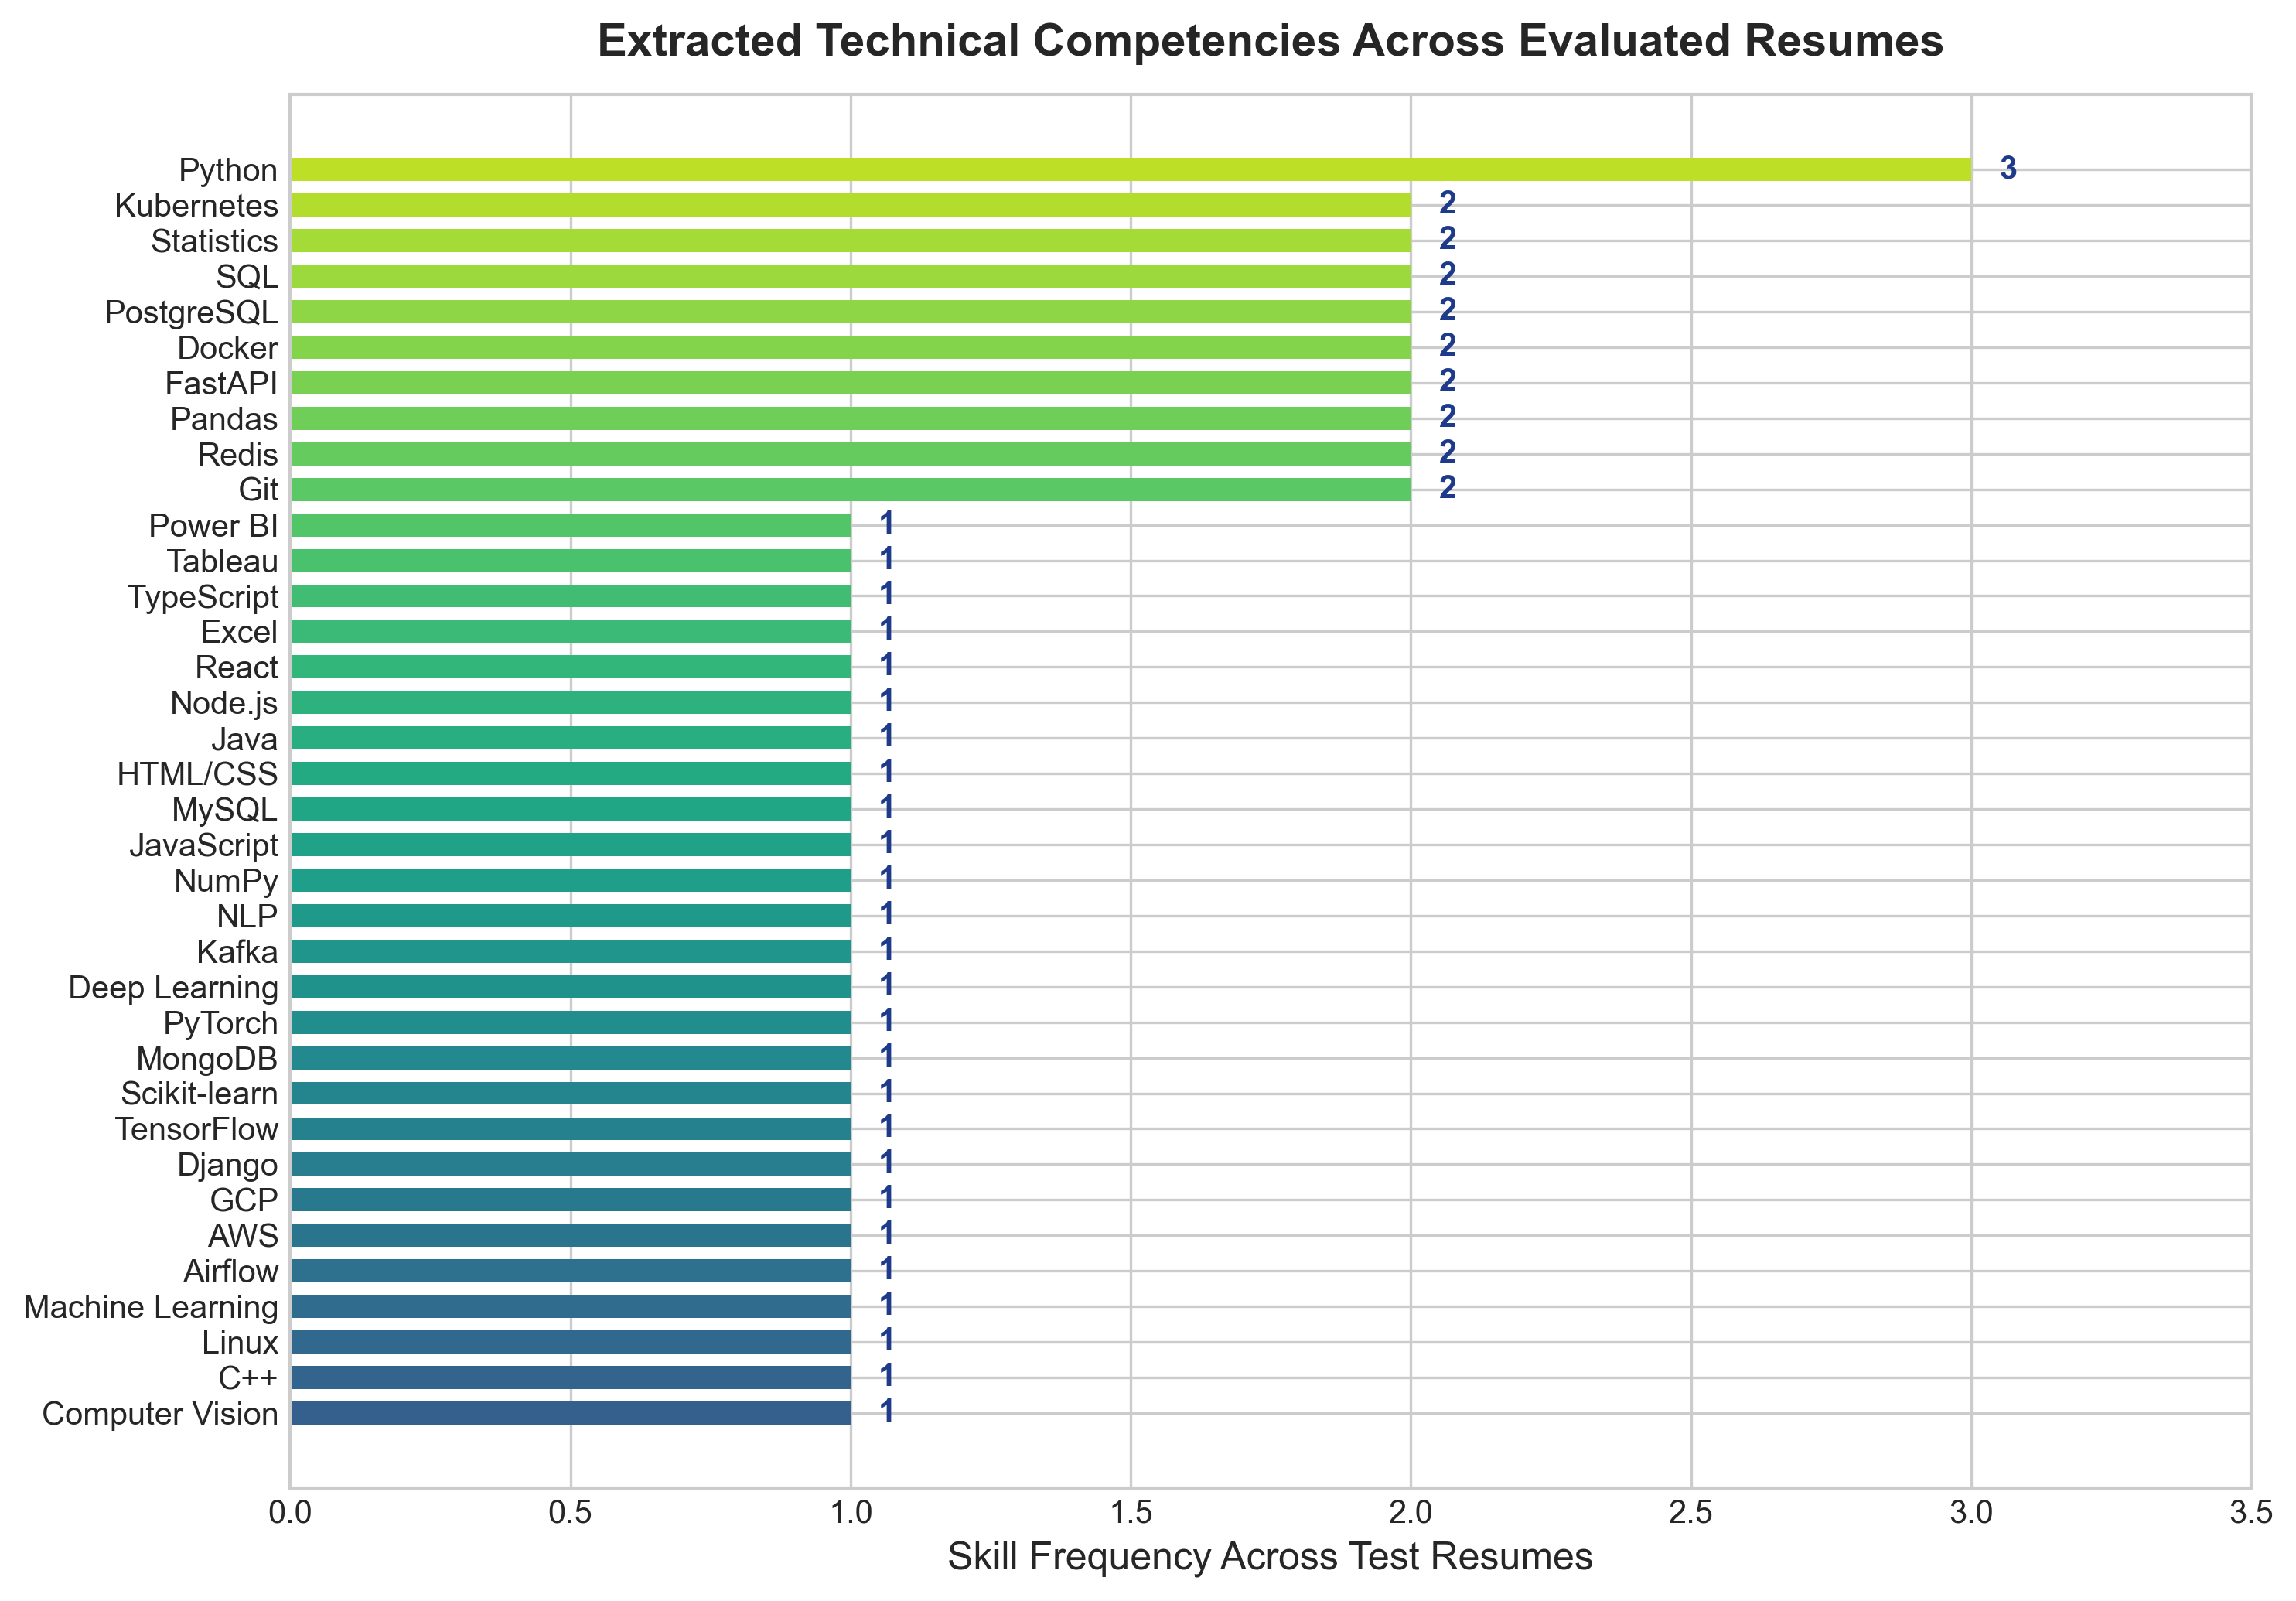

In [7]:
# Aggregate skills across test profiles
all_extracted_skills = []
for name, pdf_bytes in test_resumes.items():
    res = parse_resume(pdf_bytes)
    all_extracted_skills.extend(res['extracted_skills'])

skill_series = pd.Series(all_extracted_skills).value_counts().sort_values(ascending=True)

# Plot skill distribution
fig, ax = plt.subplots(figsize=(10, 7), dpi=300)
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(skill_series)))
bars = ax.barh(skill_series.index, skill_series.values, color=colors, height=0.65)
ax.set_xlabel('Skill Frequency Across Test Resumes', fontsize=12)
ax.set_title('Extracted Technical Competencies Across Evaluated Resumes', fontsize=14, fontweight='bold', pad=12)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.05, bar.get_y() + bar.get_height()/2, f'{int(w)}', va='center', fontsize=10, fontweight='bold', color='#1E3A8A')
ax.set_xlim(0, max(skill_series.values) + 0.5)
plt.tight_layout()

figures_dir = os.path.join('..', 'reports', 'figures') if os.path.exists(os.path.join('..', 'reports', 'figures')) else os.path.join('reports', 'figures')
os.makedirs(figures_dir, exist_ok=True)
fig.savefig(os.path.join(figures_dir, 'resume_skill_extraction_counts.png'))
plt.show()

### 8. Findings, Governance & System Limitations

#### Architectural Strengths:
1. **High Throughput & Zero Disk Footprint:** By parsing directly from byte streams in-memory via PyMuPDF, the engine eliminates intermediate disk I/O and adheres to privacy-by-design.
2. **Strict Disambiguation:** Precision regex rules prevent partial substring overlaps (e.g. `Java` vs `JavaScript`, `py` vs `spying`, `React` vs `reacting`).
3. **Scanned PDF Resilience:** Rather than crashing or returning false positives, image-only PDFs trigger an explicit warning message informing the candidate that OCR is not supported.

#### Known Limitations:
- **Scanned Image Resumes:** PDFs consisting entirely of flattened raster images require Optical Character Recognition (OCR, e.g. Tesseract), which is intentionally excluded to preserve lightweight backend execution.
- **Multi-Column Formatting:** In multi-column or tabular layouts, standard line-by-line reading orders can occasionally interleave text between adjacent columns. PyMuPDF text blocks mitigate this, but complex graphic-heavy templates may require layout-aware block sorting.